# Mentor–mentee matching demonstration

This notebook shows how the selected model (LR) turns course–competency relevance into a ranking of mentors for a mentee’s development need.

* **Mentors** are *illustrative* profiles: each one is a set of real UniSkill courses that the mentor could teach. No real people or personal data are used.
* **Mentee needs** are real ESCO competencies (label + description) from the UniSkill records.
* **Mentor score** = the highest LR probability over all sentences of the mentor’s courses; the sentence that gives this score is shown as evidence.
* To avoid leakage, every record that belongs to a mentor’s course group is **removed from training**, so the model has never seen these courses.

In [1]:
# Paths: works in Google Colab (files in Google Drive) and on a local computer.
from pathlib import Path
import hashlib, json, re, time, warnings, platform, importlib.metadata
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/Assignment3_TulegenovaK')  # folder with manual_records.csv
except ImportError:
    BASE = Path.cwd()  # local run: the notebook sits next to manual_records.csv

RESULT = BASE / 'results'
RESULT.mkdir(exist_ok=True)
SEED = 42

versions = {'python': platform.python_version(),
            **{p: importlib.metadata.version(p) for p in ['pandas', 'numpy', 'scipy', 'scikit-learn', 'matplotlib']}}
print(json.dumps(versions, indent=2))

# Integrity check: the CSV must be the same file that was verified in the source manifest.
manifest = json.loads((BASE / 'source_manifest.json').read_text(encoding='utf-8'))
assert hashlib.sha256((BASE / 'manual_records.csv').read_bytes()).hexdigest() == manifest['manual_csv_sha256']
raw = pd.read_csv(BASE / 'manual_records.csv')
print('Manual UniSkill records:', len(raw))

{
  "python": "3.9.6",
  "pandas": "2.3.3",
  "numpy": "2.0.2",
  "scipy": "1.13.1",
  "scikit-learn": "1.6.1",
  "matplotlib": "3.9.4"
}
Manual UniSkill records: 1098


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1) Cleaning (identical to the Logistic Regression notebook)
TEXT_COLS = ['skill_label', 'skill_description', 'matched_course_sentence', 'course_title']
df = raw.copy()
for c in TEXT_COLS:
    df[c] = df[c].fillna('').astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
df = df.drop_duplicates(TEXT_COLS).reset_index(drop=True)
df['record_id'] = [f'R{i:04d}' for i in range(len(df))]
df['skill_text'] = df.skill_label + ' ' + df.skill_description
y = df.eval_all.astype(int).to_numpy()

# 2) Connected groups: records that share a course title or a course sentence stay together
parent = list(range(len(df)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
for col in ['course_title', 'matched_course_sentence']:
    seen = {}
    for i, t in enumerate(df[col]):
        k = t.casefold()
        if k in seen:
            parent[find(seen[k])] = find(i)
        else:
            seen[k] = i
df['group'] = [find(i) for i in range(len(df))]

def grouped_split(seed):
    """20% of groups -> test, 25% of the remaining groups -> validation."""
    dev, test = next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(df, groups=df.group))
    a, b = next(GroupShuffleSplit(1, test_size=0.25, random_state=seed).split(df.iloc[dev], groups=df.group.iloc[dev]))
    return dev[a], dev[b], test

# 3) Five lexical features (TF-IDF is fitted on training text only)
def jaccard(a, b):
    a, b = set(re.findall(r'\b\w+\b', a.casefold())), set(re.findall(r'\b\w+\b', b.casefold()))
    return len(a & b) / len(a | b) if a | b else 0.0
JAC_S = np.array([jaccard(a, b) for a, b in zip(df.matched_course_sentence, df.skill_label)])
JAC_T = np.array([jaccard(a, b) for a, b in zip(df.course_title, df.skill_label)])
FEATURES = ['cos_sentence', 'cos_title', 'cos_min', 'jaccard_sentence', 'jaccard_title']

def lexical_features(train_idx):
    vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=20000, norm='l2')
    t = df.iloc[train_idx]
    vec.fit(pd.concat([t.course_title, t.matched_course_sentence, t.skill_text]).tolist())
    sk, ti, se = (vec.transform(df[c]) for c in ['skill_text', 'course_title', 'matched_course_sentence'])
    cs = np.asarray(se.multiply(sk).sum(1)).ravel()
    ct = np.asarray(ti.multiply(sk).sum(1)).ravel()
    return np.column_stack([cs, ct, np.minimum(cs, ct), JAC_S, JAC_T])

# 4) Threshold choice on validation data and evaluation helpers
THRESHOLDS = np.linspace(0.05, 0.95, 19)
def pick_threshold(y_val, p_val, grid=THRESHOLDS):
    scores = [(f1_score(y_val, p_val >= t, average='macro', zero_division=0), t) for t in grid]
    best = max(s for s, _ in scores)
    return min((t for s, t in scores if s == best), key=lambda t: (abs(t - 0.5), t))

def evaluate(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0),
                f1_match=f1_score(y_true, y_pred, zero_division=0),
                macro_f1=f1_score(y_true, y_pred, average='macro', zero_division=0),
                TN=int(cm[0, 0]), FP=int(cm[0, 1]), FN=int(cm[1, 0]), TP=int(cm[1, 1]))

train_idx, val_idx, test_idx = grouped_split(SEED)
X = lexical_features(train_idx)
print('Clean records:', len(df), '| classes:', dict(zip(*np.unique(y, return_counts=True))))
print('Connected groups:', df.group.nunique(), '| largest group:', df.groupby('group').size().max())
print('Split sizes (train / validation / test):', len(train_idx), len(val_idx), len(test_idx))
assert (len(train_idx), len(val_idx), len(test_idx)) == (649, 231, 216), 'Split differs from the LR notebook'
for a, b in [(train_idx, val_idx), (train_idx, test_idx), (val_idx, test_idx)]:
    assert not set(df.group.iloc[a]) & set(df.group.iloc[b])
print('Feature matrix:', X.shape)

Clean records: 1096 | classes: {np.int64(0): np.int64(700), np.int64(1): np.int64(396)}
Connected groups: 544 | largest group: 21
Split sizes (train / validation / test): 649 231 216
Feature matrix: (1096, 5)


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

def make_models(seed):
    """Hyperparameters are fixed in advance and identical for every split."""
    return {
        'LR': make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=1000, class_weight='balanced', random_state=seed)),
        'RF': RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight='balanced', random_state=seed, n_jobs=-1),
        'GB': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=seed),
    }
NAMES = {'LR': 'Logistic regression', 'RF': 'Random forest', 'GB': 'Gradient boosting',
         'Cosine': 'Cosine baseline', 'Majority': 'Majority baseline'}

## 1. Illustrative mentor profiles and mentee needs

In [4]:
MENTORS = {
    'Mentor A (databases)': ['Data Modeling and Design', 'Advanced Course in Databases', 'Big Data Platforms D'],
    'Mentor B (security)': ['Cybersecurity D', 'System and Application Security', 'Privacy and Security for Software Systems'],
    'Mentor C (user experience)': ['User Experience Design and Evaluation', 'Requirements Engineering'],
    'Mentor D (business analytics)': ['Creating Domain Value with Data', 'Data-Driven Marketing', 'Financial Statement Analysis'],
    'Mentor E (telecommunications)': ['Antennas', 'Telecommunication Engineering', 'Advanced Networking D'],
}
EXPECTED = {'query languages': 'Mentor A (databases)', 'cyber security': 'Mentor B (security)',
            "assess users' interaction with ICT applications": 'Mentor C (user experience)',
            'perform market research': 'Mentor D (business analytics)',
            'ICT communications protocols': 'Mentor E (telecommunications)',
            'track key performance indicators': 'Mentor D (business analytics)'}

courses = {t for ts in MENTORS.values() for t in ts}
missing = courses - set(df.course_title)
assert not missing, missing
needs = (df[df.skill_label.isin(EXPECTED)].drop_duplicates('skill_label')
         .set_index('skill_label').loc[list(EXPECTED), ['skill_description', 'skill_text']])
mentor_rows = df[df.course_title.isin(courses)].drop_duplicates(['course_title', 'matched_course_sentence'])
mentor_groups = set(df[df.course_title.isin(courses)].group)
train_mask = ~df.group.isin(mentor_groups)
print('Mentor course sentences:', len(mentor_rows), '| training records after removing mentor groups:', int(train_mask.sum()))
for k, v in needs.skill_description.items():
    print(f'- {k}: {v[:110]}...')

Mentor course sentences: 55 | training records after removing mentor groups: 993
- query languages: The field of standardised computer languages for retrieval of information from a database and of documents con...
- cyber security: The methods and best practices that protect ICT systems, networks, computers, devices, services, processes and...
- assess users' interaction with ICT applications: Evaluate how users interact with ICT applications in order to analyse their behaviour, draw conclusions (for i...
- perform market research: Gather, assess and represent data about target market and customers in order to facilitate strategic developme...
- ICT communications protocols: The system of rules which allow the exchange of information between computers or other devices via computer ne...
- track key performance indicators: Identify the quantifiable measures that a company or industry uses to gauge or compare performance in terms of...


## 2. Train LR without the mentors’ courses and score every need–mentor pair

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
tr = np.where(train_mask)[0]
vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=20000, norm='l2')
vec.fit(pd.concat([df.course_title.iloc[tr], df.matched_course_sentence.iloc[tr], df.skill_text.iloc[tr]]).tolist())
def pair_features(label, skill_text, titles, sentences):
    sk = vec.transform([skill_text] * len(titles))
    cs = np.asarray(vec.transform(sentences).multiply(sk).sum(1)).ravel()
    ct = np.asarray(vec.transform(titles).multiply(sk).sum(1)).ravel()
    js = np.array([jaccard(s, label) for s in sentences]); jt = np.array([jaccard(t, label) for t in titles])
    return np.column_stack([cs, ct, np.minimum(cs, ct), js, jt])

# Training features: the same five features as in the experiment
sk = vec.transform(df.skill_text.iloc[tr]); se = vec.transform(df.matched_course_sentence.iloc[tr]); ti = vec.transform(df.course_title.iloc[tr])
c1 = np.asarray(se.multiply(sk).sum(1)).ravel(); c2 = np.asarray(ti.multiply(sk).sum(1)).ravel()
Xtr = np.column_stack([c1, c2, np.minimum(c1, c2), JAC_S[tr], JAC_T[tr]])
lr = make_models(SEED)['LR'].fit(Xtr, y[tr])

rows = []
for need, r in needs.iterrows():
    for mentor, titles in MENTORS.items():
        m = mentor_rows[mentor_rows.course_title.isin(titles)]
        p = lr.predict_proba(pair_features(need, r.skill_text, m.course_title.tolist(), m.matched_course_sentence.tolist()))[:, 1]
        i = int(np.argmax(p))
        rows.append(dict(need=need, mentor=mentor, score=p[i], evidence_course=m.course_title.iloc[i],
                         evidence_sentence=m.matched_course_sentence.iloc[i][:120]))
S = pd.DataFrame(rows)
S['rank'] = S.groupby('need').score.rank(ascending=False, method='first').astype(int)
S.to_csv(RESULT / 'mentor_ranking_demo.csv', index=False)
top = S[S['rank'] == 1].set_index('need').loc[list(EXPECTED)]
top['expected_mentor'] = [EXPECTED[n] for n in top.index]
top['expected_rank'] = [int(S[(S.need == n) & (S.mentor == EXPECTED[n])]['rank'].iloc[0]) for n in top.index]
pd.set_option('display.max_colwidth', 70)
print(top[['mentor', 'score', 'expected_mentor', 'expected_rank', 'evidence_course']].to_string())
print('\nExpected mentor ranked first for', int((top.expected_rank == 1).sum()), 'of', len(top), 'needs;',
      'mean rank of expected mentor =', round(top.expected_rank.mean(), 2))

                                                                        mentor     score                expected_mentor  expected_rank                  evidence_course
need                                                                                                                                                                   
query languages                                           Mentor A (databases)  0.575617           Mentor A (databases)              1     Advanced Course in Databases
cyber security                                             Mentor B (security)  0.986861            Mentor B (security)              1                  Cybersecurity D
assess users' interaction with ICT applications  Mentor D (business analytics)  0.658998     Mentor C (user experience)              5  Creating Domain Value with Data
perform market research                                   Mentor A (databases)  0.491861  Mentor D (business analytics)              2             Big Data Plat

## 3. Figure: relevance matrix (mentee needs x mentors)

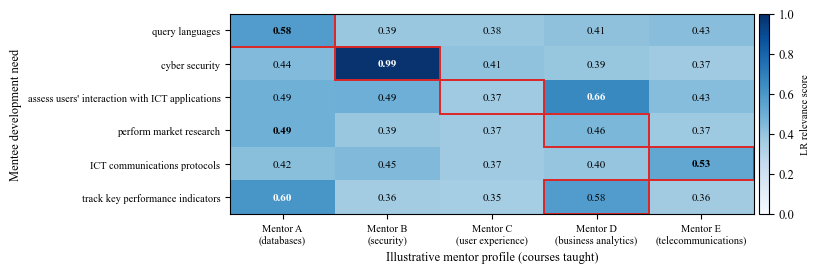

In [6]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'], 'font.size': 9})
P = S.pivot(index='need', columns='mentor', values='score').loc[list(EXPECTED), list(MENTORS)]
fig, ax = plt.subplots(figsize=(7.0, 2.6))
im = ax.imshow(P.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
for i in range(P.shape[0]):
    for j in range(P.shape[1]):
        v = P.values[i, j]; best = v == P.values[i].max()
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, fontweight='bold' if best else 'normal',
                color='white' if v > 0.6 else 'black')
        if P.columns[j] == EXPECTED[P.index[i]]:
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec='#dc2626', lw=1.4))
ax.set_xticks(range(P.shape[1]), [c.replace(' (', '\n(') for c in P.columns], fontsize=7.5)
ax.set_yticks(range(P.shape[0]), P.index, fontsize=7.5)
ax.set_xlabel('Illustrative mentor profile (courses taught)'); ax.set_ylabel('Mentee development need')
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label('LR relevance score', fontsize=7.5)
fig.savefig(RESULT / 'fig3_mentor_matching.png', dpi=300, bbox_inches='tight'); plt.show()

## 4. Interpretation

Red frames mark the mentor that a human would expect for each need; bold values are the top-ranked mentor. When the need and the mentor’s courses share vocabulary, LR ranks the expected mentor first. When the competency is phrased differently from the course text, the score drops - the same paraphrase problem found in the content analysis. The ranking should therefore be shown to coordinators as evidence-backed suggestions, not as automatic assignments.